Imports and paths

In [126]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [127]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"
processed_data_dir = ROOT / "data" / "processed"
reports_figures = ROOT / "reports" / "figures"

Loading the data

In [128]:
pl_players_2025_26 = pd.read_csv(processed_data_dir / "pl_players_2025_26.csv")
pl_players_2025_26.tail()

,player_id,name,club_id,club,position,sub_position,foot,height_in_cm,international_caps,age,contract_years_left,appearances,minutes_played,goals,assists,yellow_cards,value_start_eur,value_end_eur,value_change_eur,value_change_pct
563,1141628,Yunus Konak,1148,Brentford FC,Midfield,Defensive Midfield,right,181.0,16.0,20.4,3.1,0,0,0,0,0,4500000.0,4000000.0,-500000.0,-11.1
564,1193867,Pedro Lima,543,Wolverhampton Wanderers,Defender,Right-Back,right,174.0,1.0,19.9,3.1,9,259,0,0,0,5000000.0,4000000.0,-1000000.0,-20.0
565,1230661,Mateus Mané,543,Wolverhampton Wanderers,Midfield,Attacking Midfield,right,175.0,2.0,18.7,3.1,27,1790,3,2,0,200000.0,20000000.0,19800000.0,9900.0
566,1283997,Diego León,985,Manchester United,Defender,Left-Back,left,177.0,1.0,19.1,3.1,0,0,0,0,0,4000000.0,4000000.0,0.0,0.0
567,1322090,Jocelin Ta Bi,289,Sunderland AFC,Attack,Right Winger,left,175.0,3.0,21.3,4.1,1,39,0,0,0,125000.0,3000000.0,2875000.0,2300.0


Market value change during the season by age: one point per player, and the mean change for each age group.

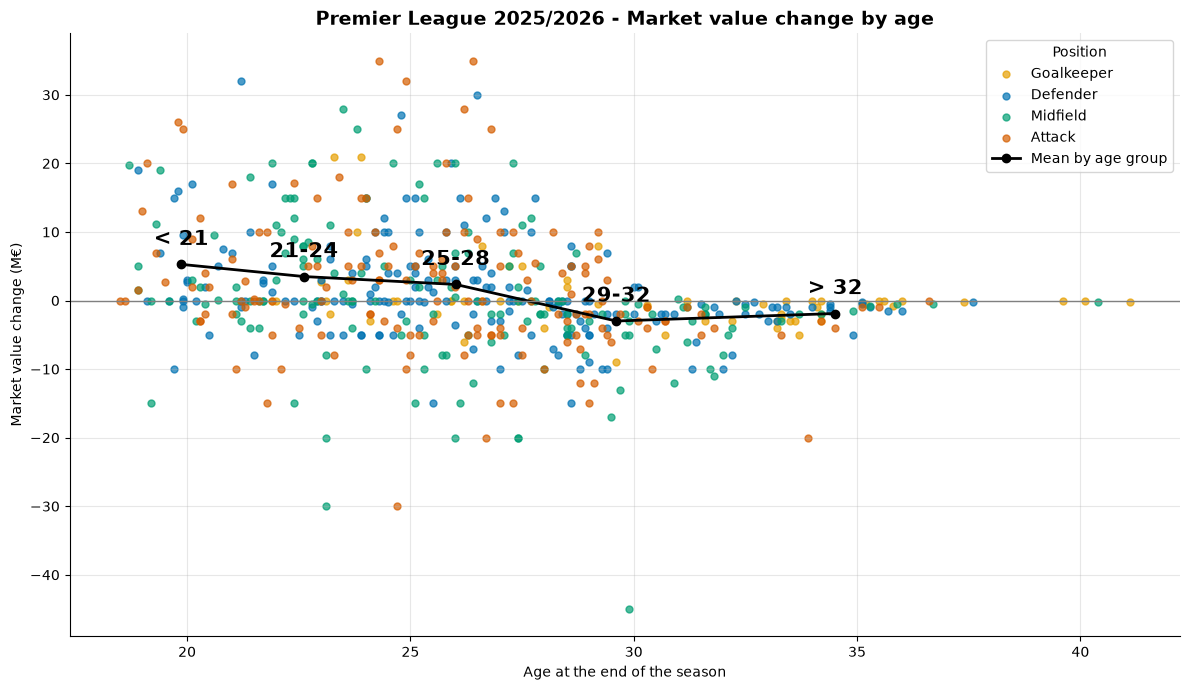

In [129]:
positions = ["Goalkeeper", "Defender", "Midfield", "Attack"]
colors = {"Goalkeeper": "#E69F00", "Defender": "#0072B2", "Midfield": "#009E73", "Attack": "#D55E00"}

age_groups = pd.cut(pl_players_2025_26["age"], bins=[0, 21, 24, 28, 32, 50], labels=["< 21", "21-24", "25-28", "29-32", "> 32"])
mean_by_age_group = pl_players_2025_26.groupby(age_groups, observed=True).agg(
    age=("age", "mean"), value_change_eur=("value_change_eur", "mean")
)

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    p = pl_players_2025_26[pl_players_2025_26["position"] == pos]
    ax.scatter(p["age"], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_age_group["age"], mean_by_age_group["value_change_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Mean by age group")
for group, row in mean_by_age_group.iterrows():
    ax.annotate(group, (row["age"], row["value_change_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black")

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Age at the end of the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by age", fontsize=14, fontweight="bold")
ax.legend(loc="upper right", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "age_vs_value_change.png", dpi=150)
plt.show()

In [130]:
pl_players_2025_26.groupby(age_groups).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
)

,players,mean_value_change_m_eur
age,,
< 21,54,5.3
21-24,122,3.5
25-28,197,2.3
29-32,127,-3.0
> 32,68,-1.9


On average, the market value change decreases with age: young players gain value during the season, while players over 29 lose value, with the lowest mean between 29 and 32 (−3.0 M€).

Market value change during the season by seasons of contract left. The players without a contract end date are not on this chart.

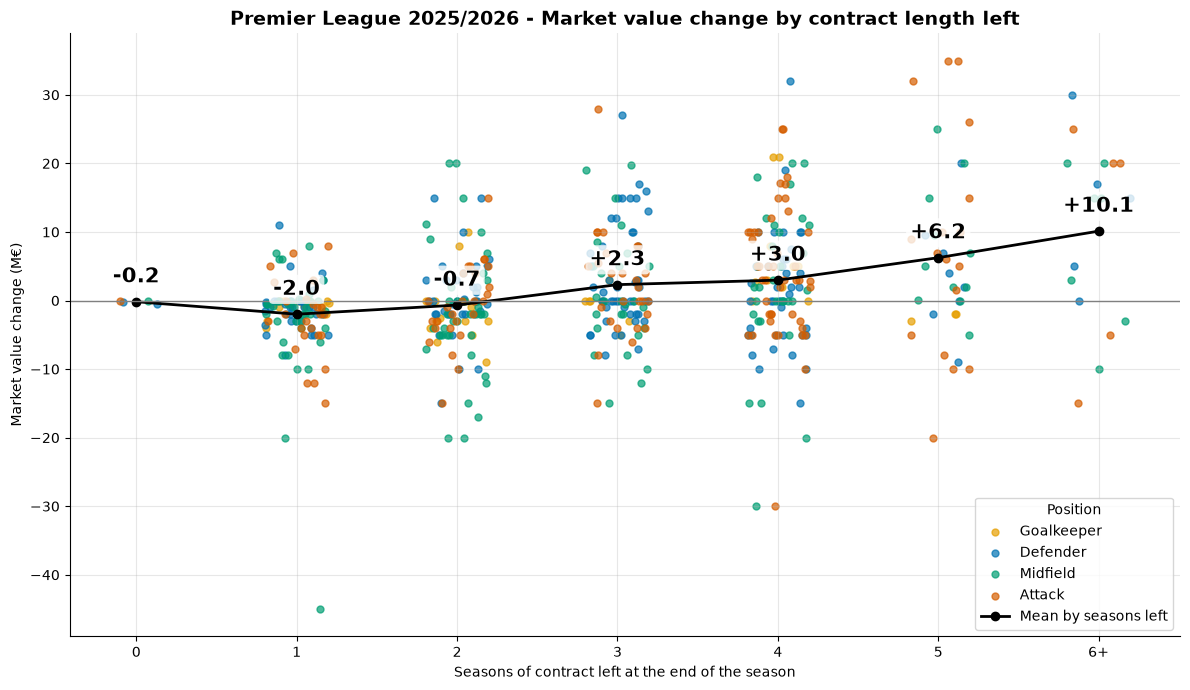

In [131]:
with_contract = pl_players_2025_26.dropna(subset=["contract_years_left"])

# The contracts end in June, so the years left are almost always x.1: round them to full seasons left.
seasons_left = with_contract["contract_years_left"].round().astype(int).clip(upper=6)
seasons_left_labels = {n: "6+" if n == 6 else str(n) for n in range(7)}
mean_by_seasons_left = with_contract.groupby(seasons_left)["value_change_eur"].mean()

# Small horizontal shift of the points, so the players with the same contract length do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.2, 0.2, len(with_contract))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (with_contract["position"] == pos).to_numpy()
    p = with_contract[is_pos]
    ax.scatter(seasons_left[is_pos] + jitter[is_pos], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_seasons_left.index, mean_by_seasons_left / 1e6, color="black", linewidth=2, marker="o", label="Mean by seasons left")
for n, value in mean_by_seasons_left.items():
    ax.annotate(f"{value / 1e6:+.1f}", (n, value / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="grey", linewidth=1)
ax.set_xticks(list(seasons_left_labels), list(seasons_left_labels.values()))
ax.set_xlabel("Seasons of contract left at the end of the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by contract length left", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "contract_vs_value_change.png", dpi=150)
plt.show()

In [132]:
with_contract.groupby(seasons_left.map(seasons_left_labels).rename("seasons_left"), sort=False).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
).sort_index()

,players,mean_value_change_m_eur
seasons_left,,
0,4,-0.2
1,117,-2.0
2,117,-0.7
3,110,2.3
4,127,3.0
5,39,6.2
6+,17,10.1


The longer the contract has left, the more the value rises, almost uniformly. Players with one year left on their contracts lose an average of 2 M€.

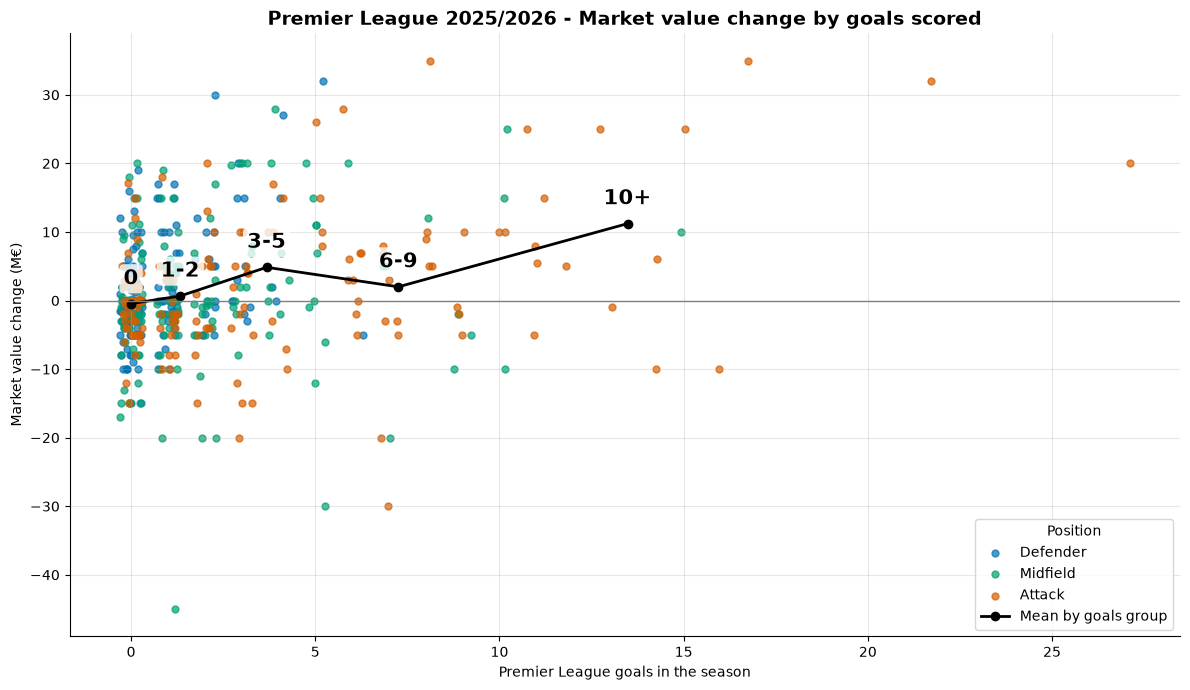

In [133]:
outfield_players = pl_players_2025_26[pl_players_2025_26["position"] != "Goalkeeper"]

goal_groups = pd.cut(outfield_players["goals"], bins=[-1, 0, 2, 5, 9, 40], labels=["0", "1-2", "3-5", "6-9", "10+"])
mean_by_goal_group = outfield_players.groupby(goal_groups, observed=True).agg(
    goals=("goals", "mean"), value_change_eur=("value_change_eur", "mean")
)

# Small horizontal shift of the points, so the players with the same number of goals do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(outfield_players))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions[1:]:
    is_pos = (outfield_players["position"] == pos).to_numpy()
    p = outfield_players[is_pos]
    ax.scatter(p["goals"] + jitter[is_pos], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_goal_group["goals"], mean_by_goal_group["value_change_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Mean by goals group")
for group, row in mean_by_goal_group.iterrows():
    ax.annotate(group, (row["goals"], row["value_change_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Premier League goals in the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by goals scored", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "goals_vs_value_change.png", dpi=150)
plt.show()

In [134]:
outfield_players.groupby(goal_groups, observed=True).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
)

,players,mean_value_change_m_eur
goals,,
0,230,-0.5
1-2,149,0.7
3-5,72,4.8
6-9,35,2.0
10+,21,11.2


The more goals you score, the higher the value goes, with a big jump at 10+ goals.
The drop for the 6-9 goals group (+2.0 M€), below the 3-5 goals group (+4.8 M€) needs to be looked at, we can make a hypothesis that the group is mainly composed of defensive and midfield players. 

In [135]:
is_3_to_9_goals = goal_groups.isin(["3-5", "6-9"])

pd.crosstab(
    goal_groups[is_3_to_9_goals].cat.remove_unused_categories().rename("goals"),
    outfield_players.loc[is_3_to_9_goals, "position"],
)[["Defender", "Midfield", "Attack"]].assign(Total=lambda t: t.sum(axis=1))

position,Defender,Midfield,Attack,Total
goals,,,,
3-5,16,30,26,72
6-9,1,8,26,35


The values say the opposite of what we expected.
The 6-9 goals group is mostly attackers (26 out of 35), while the 3-5 goals group is mostly defenders and midfielders (46 out of 72). For them, 3 to 5 goals is a very good season, which explains the higher mean value change of this group.

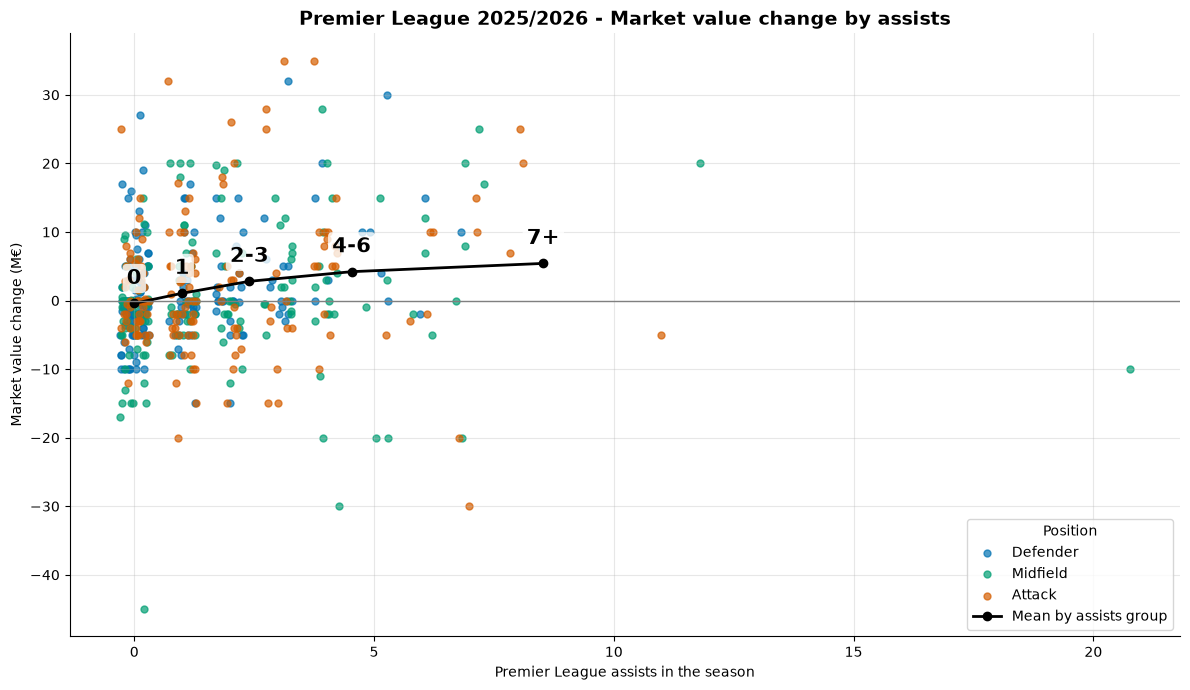

In [136]:
assist_groups = pd.cut(outfield_players["assists"], bins=[-1, 0, 1, 3, 6, 40], labels=["0", "1", "2-3", "4-6", "7+"])
mean_by_assist_group = outfield_players.groupby(assist_groups, observed=True).agg(
    assists=("assists", "mean"), value_change_eur=("value_change_eur", "mean")
)

# Small horizontal shift of the points, so the players with the same number of assists do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(outfield_players))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions[1:]:
    is_pos = (outfield_players["position"] == pos).to_numpy()
    p = outfield_players[is_pos]
    ax.scatter(p["assists"] + jitter[is_pos], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_assist_group["assists"], mean_by_assist_group["value_change_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Mean by assists group")
for group, row in mean_by_assist_group.iterrows():
    ax.annotate(group, (row["assists"], row["value_change_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Premier League assists in the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by assists", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "assists_vs_value_change.png", dpi=150)
plt.show()

In [137]:
outfield_players.groupby(assist_groups, observed=True).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
)

,players,mean_value_change_m_eur
assists,,
0,219,-0.4
1,111,1.1
2-3,102,2.8
4-6,58,4.2
7+,17,5.4


Logically, the more assists a player makes, the higher his market value rises. But as we saw earlier, it’s not a formality, as in the case of Bruno Fernandes (the green dot farthest to the right).

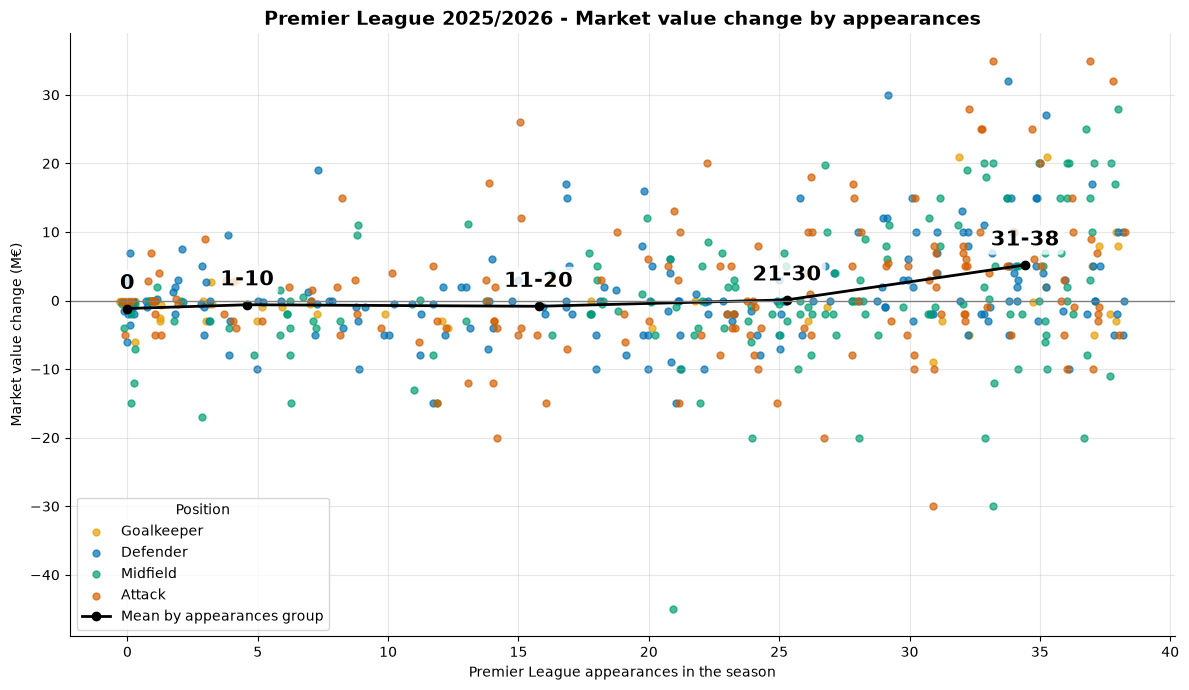

In [138]:
appearances_groups = pd.cut(pl_players_2025_26["appearances"], bins=[-1, 0, 10, 20, 30, 38], labels=["0", "1-10", "11-20", "21-30", "31-38"])
mean_by_appearances_group = pl_players_2025_26.groupby(appearances_groups, observed=True).agg(
    appearances=("appearances", "mean"), value_change_eur=("value_change_eur", "mean")
)

# Small horizontal shift of the points, so the players with the same number of appearances do not hide each other.
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(pl_players_2025_26))

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    is_pos = (pl_players_2025_26["position"] == pos).to_numpy()
    p = pl_players_2025_26[is_pos]
    ax.scatter(p["appearances"] + jitter[is_pos], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_appearances_group["appearances"], mean_by_appearances_group["value_change_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Mean by appearances group")
for group, row in mean_by_appearances_group.iterrows():
    ax.annotate(group, (row["appearances"], row["value_change_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Premier League appearances in the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by appearances", fontsize=14, fontweight="bold")
ax.legend(loc="lower left", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "appearances_vs_value_change.png", dpi=150)
plt.show()

In [139]:
pl_players_2025_26.groupby(appearances_groups, observed=True).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
)

,players,mean_value_change_m_eur
appearances,,
0,52,-1.2
1-10,109,-0.6
11-20,92,-0.8
21-30,150,0.1
31-38,165,5.2


A player who never or barely plays will see his market value decrease, while an undisputed starter will see its value increase

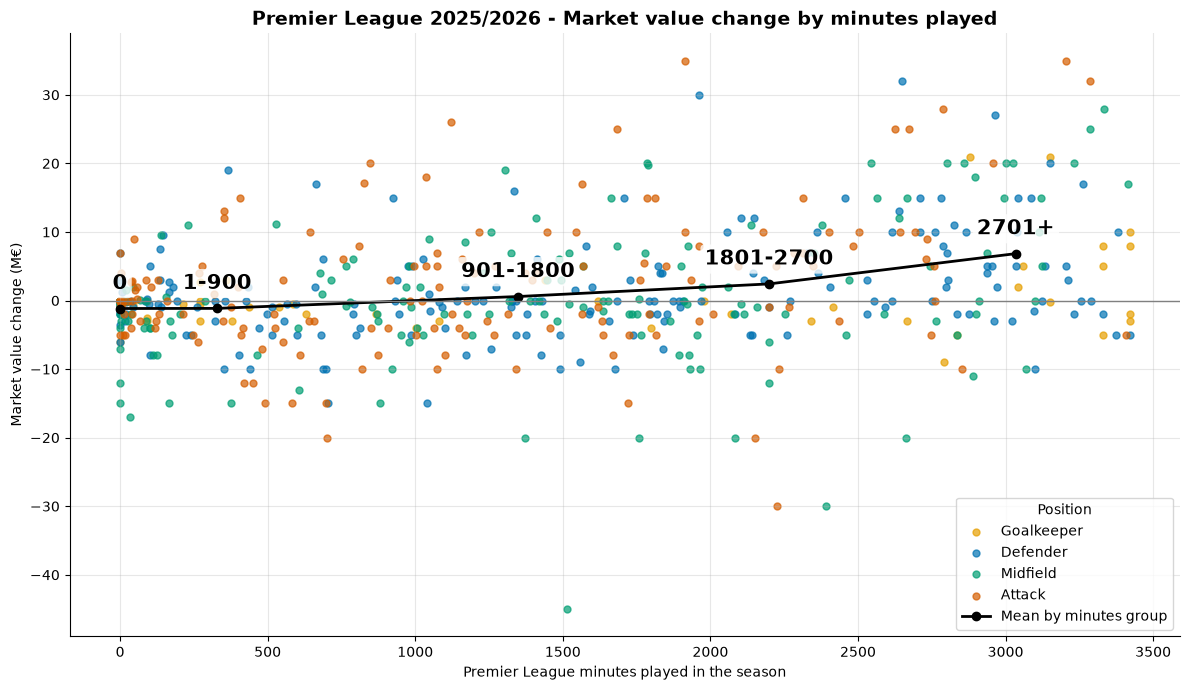

In [140]:
minutes_groups = pd.cut(pl_players_2025_26["minutes_played"], bins=[-1, 0, 900, 1800, 2700, 3420], labels=["0", "1-900", "901-1800", "1801-2700", "2701+"])
mean_by_minutes_group = pl_players_2025_26.groupby(minutes_groups, observed=True).agg(
    minutes_played=("minutes_played", "mean"), value_change_eur=("value_change_eur", "mean")
)

fig, ax = plt.subplots(figsize=(12, 7))
for pos in positions:
    p = pl_players_2025_26[pl_players_2025_26["position"] == pos]
    ax.scatter(p["minutes_played"], p["value_change_eur"] / 1e6, color=colors[pos], s=25, alpha=0.7, label=pos)

ax.plot(mean_by_minutes_group["minutes_played"], mean_by_minutes_group["value_change_eur"] / 1e6, color="black", linewidth=2, marker="o", label="Mean by minutes group")
for group, row in mean_by_minutes_group.iterrows():
    ax.annotate(group, (row["minutes_played"], row["value_change_eur"] / 1e6), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=15, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Premier League minutes played in the season")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by minutes played", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", title="Position")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(reports_figures / "minutes_vs_value_change.png", dpi=150)
plt.show()

In [141]:
pl_players_2025_26.groupby(minutes_groups, observed=True).agg(
    players=("player_id", "count"),
    mean_value_change_m_eur=("value_change_eur", lambda x: round(x.mean() / 1e6, 1)),
)

,players,mean_value_change_m_eur
minutes_played,,
0,52,-1.2
1-900,176,-1.1
901-1800,150,0.6
1801-2700,104,2.4
2701+,86,6.8


The more a player plays, the more important he is, and the more his market value goes up. 

In [142]:
pl_players_2025_26.columns.to_list()

['player_id',
 'name',
 'club_id',
 'club',
 'position',
 'sub_position',
 'foot',
 'height_in_cm',
 'international_caps',
 'age',
 'contract_years_left',
 'appearances',
 'minutes_played',
 'goals',
 'assists',
 'yellow_cards',
 'value_start_eur',
 'value_end_eur',
 'value_change_eur',
 'value_change_pct']

Market value change by position

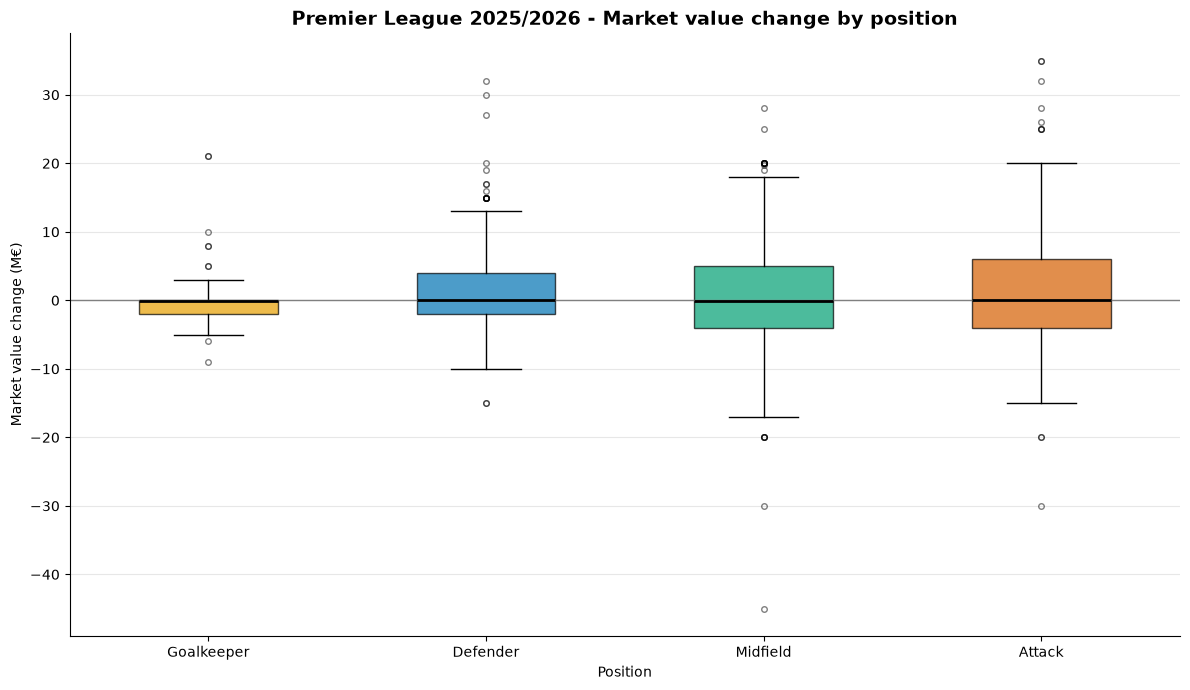

In [143]:
fig, ax = plt.subplots(figsize=(12, 7))
boxes = ax.boxplot(
    [pl_players_2025_26.loc[pl_players_2025_26["position"] == pos, "value_change_eur"] / 1e6 for pos in positions],
    tick_labels=positions, patch_artist=True, widths=0.5,
    medianprops=dict(color="black", linewidth=2), flierprops=dict(marker="o", markersize=4, alpha=0.5),
)
for box, pos in zip(boxes["boxes"], positions):
    box.set_facecolor(colors[pos])
    box.set_alpha(0.7)

ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Position")
ax.set_ylabel("Market value change (M€)")
ax.set_title("Premier League 2025/2026 - Market value change by position", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
fig.savefig(reports_figures / "position_vs_value_change.png", dpi=150)
plt.show()

In [144]:
box_by_position = pl_players_2025_26.groupby("position")["value_change_eur"].agg(
    box_low_m_eur=lambda x: round(x.quantile(0.25) / 1e6, 1),
    box_high_m_eur=lambda x: round(x.quantile(0.75) / 1e6, 1),
).reindex(positions)
box_by_position["box_spread_m_eur"] = box_by_position["box_high_m_eur"] - box_by_position["box_low_m_eur"]
box_by_position

,box_low_m_eur,box_high_m_eur,box_spread_m_eur
position,,,
Goalkeeper,-2.0,0.0,2.0
Defender,-2.0,4.0,6.0
Midfield,-4.0,5.0,9.0
Attack,-4.0,6.0,10.0


The median value change is close to 0 for every position: the position alone does not make a typical player gain or lose value. What changes is the spread: goalkeepers’ values barely move, while attackers have the widest range, with both the biggest gains and some of the biggest losses.

The greater the spread, the less certain it becomes what will happen to a player's value. For a goalkeeper, you can assume that there will be pretty much no change. For a forward, it all depends on how his season goes.

Correlation between each criterion and the market value change

<Axes: >

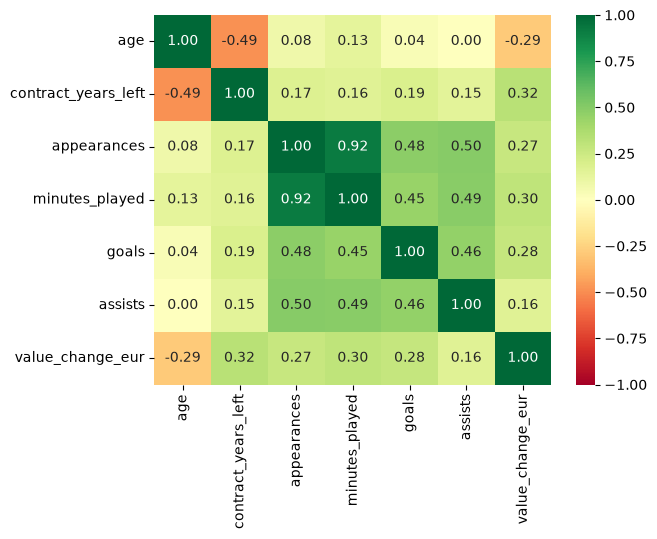

In [145]:
corr_columns = pl_players_2025_26[
    ["age", "contract_years_left", "appearances", "minutes_played",
     "goals", "assists", "value_change_eur"]
]

co_mtx = corr_columns.corr()

sns.heatmap(co_mtx, cmap="RdYlGn", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f")

In [146]:
co_mtx["value_change_eur"].drop("value_change_eur").sort_values()

age                   -0.288910
assists                0.163544
appearances            0.265742
goals                  0.280893
minutes_played         0.299044
contract_years_left    0.321091
Name: value_change_eur, dtype: float64

All the criteria are linked to the value change in the expected direction, but each link is weak to moderate (around 0.3): no criterion explains the value change alone. Appearances and minutes played are almost the same information (0.92 between them), and age and contract length are linked (−0.49), so the model will have to separate their effects.

## Conclusion

- **Age**: young players gain value during the season, players over 29 lose value.
- **Contract**: the more seasons of contract left, the more the value rises. Players with one season left lose value. A player whose contract is coming to its end tends to have a lower market value, because his club has less negotiating power and risks losing him for free when his contract expires.
- **Playing time**: starters gain value, players who barely play lose value. Appearances and minutes played give almost the same information, the minutes are more precise.
- **Goals and assists**: they make the value rise, but the same number of goals does not mean the same thing for each position.
- **Position**: alone, it does not change the value of a typical player, only the spread.

No criterion explains the market value change alone, and some of them are linked (age and contract length). The next step is a model that takes them all into account.